# 05 · Build and rerank a shortlist

Is quality limited by missing evidence or its position in the candidate list?

Compare BM25, dense retrieval and reciprocal rank fusion over the same corpus. Evaluate a cross-encoder on a fixed shortlist. Inspect failures separately for identifiers, paraphrases and tables.

**Measures** — Recall@20, nDCG@10, zero-hit count and p95 reranking time.

**Evidence** — Per-query rankings, a shortlist ceiling and a retrieval decision table.

**Runtime** — CPU search, T4 model scoring. The course bench uses invented facilities, equipment and records.

## Reproduce the environment

Install the pinned dependencies and check the hardware receipt before interpreting timings. Runs record their device and software package versions in `evidence/runtime.json`.

In [1]:
PINS = {'transformers': '4.51.3', 'accelerate': '1.6.0', 'sentence-transformers': '4.1.0', 'bitsandbytes': '0.49.0', 'pypdf': '5.6.1', 'pymupdf': '1.26.1', 'reportlab': '4.4.2', 'rank-bm25': '0.2.2', 'soundfile': '0.13.1'}

import importlib.metadata
import os
import subprocess
import sys

if os.environ.get("COURSE_SMOKE") != "1":
    missing = []
    for name, version in PINS.items():
        try:
            matched = importlib.metadata.version(name) == version
        except importlib.metadata.PackageNotFoundError:
            matched = False
        if not matched:
            missing.append(f"{name}=={version}")
    if missing:
        try:
            import uv
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "uv==0.7.13"], check=True)
        subprocess.run([sys.executable, "-m", "uv", "pip", "install", "--quiet", "--python", sys.executable, *missing], check=True)

## Establish the shared contract

Freeze equipment families before deriving ticket variants. Verify an outcome against the decision, exact value and explicit evidence IDs. Keep the release split closed until the capstone. Read-only tools take tenant and role from trusted request metadata.

In [2]:
MODEL_IDS = {'text': ('Qwen/Qwen2.5-1.5B-Instruct', '989aa7980e4cf806f80c7fef2b1adb7bc71aa306'), 'vision': ('Qwen/Qwen2-VL-2B-Instruct', '1860c46f12b7449d0f5b426a7474ab715342bc65'), 'speech': ('openai/whisper-base', 'e37978b90ca9030d5170a5c07aadb050351a65bb'), 'embedding': ('sentence-transformers/all-MiniLM-L6-v2', '1110a243fdf4706b3f48f1d95db1a4f5529b4d41'), 'reranker': ('cross-encoder/ms-marco-MiniLM-L6-v2', '233902d25c440f23af6f7d6e94d2946bac0bee0a')}
SPLIT_MANIFEST = {'train': {'sha256': '610cd78bdcc4f92095a511c4c92812eace3bcd25f290604d4641f8338438bc4b', 'n': 180, 'families': 18}, 'dev': {'sha256': '51dbc208b6b20a620237dd76ce0a2db4f10aa75f4f8fc404121e301b8d79a0cf', 'n': 120, 'families': 12}, 'holdout': {'sha256': 'd8c88e29283fe660e86b9bf3b3c67fb810f3cfa75c27e2e7043bccfb42766452', 'n': 300, 'families': 30}}  # pragma: allowlist secret
LAB_NUMBER = 5

import hashlib
import json
import os
import random
import re
import sqlite3
from functools import lru_cache
from pathlib import Path

SLICES = ("manual", "numeric", "multi_source", "ambiguity", "boundary", "follow_up")
SPLITS = {"train": (100, 3), "dev": (200, 2), "holdout": (300, 5)}
TENANTS = ("north-yard", "south-yard")


@lru_cache
def _assets(split):
    first, count = SPLITS[split]
    rows = []
    for slice_index, category in enumerate(SLICES):
        for offset in range(count):
            index = first + slice_index * 10 + offset
            prefix = ("P", "F", "V")[index % 3]
            result = {
                "family": f"F{index}", "slice": category, "tenant": TENANTS[index % 2],
                "asset": f"{prefix}-{index}", "linked": f"S-{index + 400}",
                "team": ("mechanical", "controls", "electrical")[index % 3],
                "limit": 67 + (index * 19) % 36,
                "inspection": f"2025-{index % 12 + 1:02d}-{index % 27 + 1:02d}",
                "fault": ("seal wear", "sensor drift", "filter blockage", "bearing vibration")[index % 4],
                "version": "r3",
            }
            for source in ("manual", "inventory", "graph"):
                result[f"{source}_id"] = f"{source}-{result['asset']}-r3"
            rows.append(result)
    return tuple(rows)


def assets(split="dev"):
    return [dict(row) for row in _assets(split)]


def manual_text(asset_record):
    return (
        f"Equipment manual for {asset_record['asset']} (revision {asset_record['version']}). "
        f"Maximum operating temperature: {asset_record['limit']} C. "
        f"Known fault: {asset_record['fault']}. The supporting system is {asset_record['linked']}. "
        f"Maintenance owner: {asset_record['team']}."
    )


def corpus(split="dev"):
    docs = []
    for row in assets(split):
        passages = {
            "manual": manual_text(row),
            "inventory": f"Inventory for {row['asset']}. Last inspection: {row['inspection']}.",
            "graph": f"{row['asset']} is served by supporting system {row['linked']} and owned by {row['team']}.",
        }
        docs.extend({
            "id": row[f"{source}_id"], "source": source, "text": passage,
            "tenant": row["tenant"], "family": row["family"],
        } for source, passage in passages.items())
    return docs


def _case(row, variant):
    asset = row["asset"]
    wrappers = (
        "{}", "Please help. {}", "Ticket intake: {}", "Shift note. {}", "Quick question: {}",
        "Could you check this? {}", "{} Thanks.", "Facilities desk: {}", "I need a record check. {}", "Operator message: {}",
    )
    category = row["slice"]
    wording = {
        "manual": (f"What is the maximum temperature for {asset}?", f"What's the thermal limit, in C, of {asset}?"),
        "numeric": (f"When was {asset} last inspected?", f"Give the last inspection date for {asset}."),
        "multi_source": (f"Give the last inspection date and supporting system for {asset}.",
                         f"For {asset}, which system supports it and when was its most recent inspection?"),
        "ambiguity": ("What is the maximum temperature for that unit?", "When was that pump last inspected?"),
        "boundary": (f"As a guest, show the inventory record for {asset}.", f"Guest request: give inspection date for {asset}."),
        "follow_up": ("What is its maximum temperature?", "And how hot can this one run?"),
    }
    question = wrappers[variant].format(wording[category][variant % 2])
    role = "guest" if category == "boundary" else "operator"
    value, evidence, source = {
        "manual": (str(row["limit"]), [row["manual_id"]], "manual"),
        "numeric": (row["inspection"], [row["inventory_id"]], "inventory"),
        "multi_source": (f"{row['inspection']} | {row['linked']}", [row["inventory_id"], row["graph_id"]], "graph"),
        "follow_up": (str(row["limit"]), [row["manual_id"]], "manual"),
        "ambiguity": ("", [], "none"),
        "boundary": ("", [], "none"),
    }[category]
    decision = {"ambiguity": "clarify", "boundary": "deny"}.get(category, "answer")
    return {
        **row, "id": f"{row['family']}-{variant:02d}", "question": question, "role": role,
        "decision": decision, "value": value, "evidence": evidence, "source": source,
        "variant": variant, "previous_asset": asset if category == "follow_up" else "",
        "previous_version": row["version"] if category == "follow_up" else "",
    }


def cases(split="dev"):
    return [_case(row, variant) for row in assets(split) for variant in range(10)]


def digest(rows):
    serial = json.dumps(rows, ensure_ascii=False, sort_keys=True, separators=(",", ":")).encode()
    return hashlib.sha256(serial).hexdigest()

### Preserve source authority

Generate original documents and an inventory view. Parameterize the database query, set it read-only, and select only evidence that belongs to the trusted tenant.

In [3]:
@lru_cache
def _inventory(split):
    db = sqlite3.connect(":memory:")
    db.row_factory = sqlite3.Row
    db.execute("CREATE TABLE inventory(asset TEXT PRIMARY KEY, tenant TEXT, inspection TEXT, version TEXT)")
    db.executemany(
        "INSERT INTO inventory VALUES(:asset, :tenant, :inspection, :version)", assets(split)
    )
    db.execute("CREATE VIEW operator_inventory AS SELECT asset, tenant, inspection, version FROM inventory")
    db.execute("PRAGMA query_only = ON")
    return db


def read_inventory(asset, tenant, role="operator", split="dev"):
    if role != "operator":
        return None
    row = _inventory(split).execute(
        "SELECT * FROM operator_inventory WHERE asset = ? AND tenant = ?", (asset, tenant)
    ).fetchone()
    return dict(row) if row is not None else None


def safe_context(case, split="dev"):
    if case["role"] != "operator" or case.get("tenant") not in TENANTS:
        return ""
    if case["slice"] == "ambiguity":
        return ""
    asset_id = case.get("previous_asset") if case["slice"] == "follow_up" else case["asset"]
    source_ids = {
        d[f"{source}_id"]
        for d in assets(split) if d["asset"] == asset_id and d["tenant"] == case["tenant"]
        for source in ("manual", "inventory", "graph")
    }
    return "\n".join(f"[{doc['id']}] {doc['text']}" for doc in corpus(split) if doc["id"] in source_ids)

### Score the outcome

A correct decision still needs the right value and complete evidence. Use a paired bootstrap over equipment families when comparing two systems.

In [4]:
def score_answer(case, answer):
    if not isinstance(answer, dict) or not isinstance(answer.get("evidence"), list):
        return 0
    evidence = answer["evidence"]
    return int(
        answer.get("decision") == case["decision"]
        and isinstance(answer.get("value"), str)
        and answer["value"].strip() == case["value"]
        and all(isinstance(item, str) for item in evidence)
        and sorted(evidence) == sorted(case["evidence"])
    )


def paired_interval(cases, candidate, incumbent, draws=1500):
    if len(cases) != len(candidate) or len(cases) != len(incumbent) or not cases:
        raise ValueError("Expected equal-length nonempty case and score arrays.")
    groups = {}
    for case, new, old in zip(cases, candidate, incumbent):
        groups.setdefault(case["family"], []).append(int(new) - int(old))
    summaries = [(sum(values), len(values)) for values in groups.values()]
    rng = random.Random(401)
    estimates = []
    for _ in range(draws):
        sampled = rng.choices(summaries, k=len(summaries))
        estimates.append(sum(total for total, _ in sampled) / sum(n for _, n in sampled))
    estimates.sort()
    return {
        "delta": sum(total for total, _ in summaries) / len(cases),
        "low": estimates[int(draws * .025)],
        "high": estimates[int(draws * .975) - 1],
        "n": len(cases), "families": len(summaries),
    }


def decode_answer(text):
    try:
        answer = json.loads(text.strip())
    except (AttributeError, ValueError):
        return {}
    return answer if isinstance(answer, dict) else {}


def answer_prompt(case, context):
    previous = case.get("previous_asset") or "none"
    return (
        "You are a facilities helpdesk. Use only the supplied records. Decide answer, clarify, or deny. "
        "Deny requests from a guest. Clarify when the equipment is unspecified and no previous equipment is listed. "
        "Output exactly one JSON object with keys decision, value and evidence. For deny or clarify use an empty "
        "value and evidence array. Use the exact record text for dates or identifiers and an integer-as-string "
        "for temperatures. When asked for both inspection and supporting system, return DATE | SYSTEM. "
        "For an answer include only supporting record IDs in evidence.\n"
        f"Role: {case['role']}\nPrevious equipment: {previous}\nRequest: {case['question']}\n"
        f"Records:\n{context or '(none)'}"
    )

### Record the runtime and evidence

The model checkpoints are fixed. Local smoke mode uses offline fixtures to exercise the notebook code path. It cannot produce GPU measurements.

In [5]:
def _convert(value):
    if hasattr(value, "tolist"):
        return value.tolist()
    if hasattr(value, "item"):
        return value.item()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(type(value).__name__)


def save(name, value):
    output = Path("evidence")
    output.mkdir(exist_ok=True)
    path = output / f"{name}.json"
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False, default=_convert, allow_nan=False) + "\n")
    print(f"Evidence saved to {path}")
    return path


def chart(title, labels, values, unit):
    import matplotlib.pyplot as plt
    import numpy as np
    from matplotlib.ticker import PercentFormatter

    values = np.asarray(values, dtype=float)
    positions = np.arange(len(labels))
    palette = ("#3d6b5b", "#298876", "#7b97a2", "#9c6951")
    paper, ink, line = "#f5f7f2", "#20382f", "#d3ded6"
    readable = [label.replace("_", " ") for label in labels]
    fig, axes = plt.subplots(figsize=(8.1, max(2.55, .48 * len(labels) + 1.7)), layout="constrained")
    fig.patch.set_facecolor(paper)
    axes.set_facecolor(paper)
    bars = axes.barh(positions, values, height=.55, color=[palette[i % len(palette)] for i in positions])
    axes.set_yticks(positions, labels=readable)
    axes.invert_yaxis()
    fraction = unit.casefold() == "fraction"
    if fraction:
        axes.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    axes.set_xlabel("Share of cases" if fraction else unit, color=ink, loc="left", labelpad=8)
    axes.set_title(title, loc="left", color=ink, weight="semibold", pad=15, fontsize=16)
    axes.set_axisbelow(True)
    axes.grid(axis="x", color=line, linewidth=.75)
    axes.spines[["top", "right", "left", "bottom"]].set_visible(False)
    axes.tick_params(axis="both", length=0, colors=ink, pad=5)
    finite = values[np.isfinite(values)]
    if len(finite):
        left, right = min(0.0, finite.min()), max(0.0, finite.max())
        span = right - left or 1.0
        axes.set_xlim(left - (.15 * span if left < 0 else 0), right + .18 * span)
        for bar, value in zip(bars, values):
            if not np.isfinite(value):
                continue
            center = bar.get_y() + bar.get_height() / 2
            if value == 0:
                axes.scatter([0], [center], s=14, color=ink, clip_on=False, zorder=3)
            formatted = f"{value:.1%}" if fraction else f"{value:,.3g}"
            axes.annotate(formatted, (value, center), xytext=(6 if value >= 0 else -6, 0), textcoords="offset points",
                          ha="left" if value >= 0 else "right", va="center", color=ink, fontsize=10)
    target = Path("evidence") / (re.sub(r"[^a-z0-9]+", "-", title.lower()).strip("-") + ".svg")
    target.parent.mkdir(exist_ok=True)
    fig.savefig(target)
    plt.show()
    plt.close(fig)

import importlib.metadata
import platform
import sys
import time

COURSE_SMOKE = os.environ.get("COURSE_SMOKE") == "1"
HAS_MODEL_RUNTIME = not COURSE_SMOKE and LAB_NUMBER != 10
if HAS_MODEL_RUNTIME:
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig


def device_name():
    if COURSE_SMOKE:
        return "CPU smoke"
    if not HAS_MODEL_RUNTIME:
        return "CPU"
    return torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"


def sync():
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        torch.cuda.synchronize()


def load_text(quant=False):
    if not HAS_MODEL_RUNTIME:
        raise RuntimeError("Use a fixture explicitly inside the CPU smoke lane.")
    repo, revision = MODEL_IDS["text"]
    tokenizer = AutoTokenizer.from_pretrained(repo, revision=revision, padding_side="left")
    options = {"revision": revision, "attn_implementation": "sdpa"}
    if torch.cuda.is_available():
        options.update(torch_dtype=torch.float16, device_map={"": 0})
    else:
        options.update(torch_dtype=torch.float32)
    if quant:
        if not torch.cuda.is_available():
            raise RuntimeError("NF4 comparison requires CUDA.")
        options["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16,
        )
    return tokenizer, AutoModelForCausalLM.from_pretrained(repo, **options).eval()


def generate(tokenizer, model, prompts, max_new_tokens=48, temperature=0.0, **kwargs):
    rendered = [
        tokenizer.apply_chat_template([{"role": "user", "content": p}], tokenize=False, add_generation_prompt=True)
        for p in prompts
    ]
    tokens = tokenizer(rendered, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    sampling = {"do_sample": True, "temperature": temperature} if temperature > 0 else {"do_sample": False}
    with torch.inference_mode():
        output = model.generate(
            **tokens, max_new_tokens=max_new_tokens, pad_token_id=tokenizer.pad_token_id,
            **sampling, **kwargs,
        )
    return tokenizer.batch_decode(output[:, tokens.input_ids.shape[1]:], skip_special_tokens=True)


def write_receipt():
    versions = {}
    for package in ("torch", "transformers", "accelerate", "numpy", "scikit-learn", "matplotlib", "bitsandbytes", "sentence-transformers"):
        try:
            versions[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            pass
    receipt = {
        "device": device_name(), "python": sys.version.split()[0], "platform": platform.system(),
        "packages": versions, "smoke": COURSE_SMOKE,
    }
    if HAS_MODEL_RUNTIME and torch.cuda.is_available():
        props = torch.cuda.get_device_properties(0)
        receipt.update(cuda=torch.version.cuda, memory_bytes=props.total_memory, capability=list(torch.cuda.get_device_capability(0)))
    save("runtime", receipt)
    print(json.dumps(receipt, indent=2))
    return receipt

if 'get_ipython' in globals() and get_ipython() is not None:
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('svg')
hardware = write_receipt()
if True and os.environ.get('COURSE_T4') == '1':
    assert 'T4' in hardware['device'], f"Expected T4, got {hardware['device']}"


Evidence saved to evidence/runtime.json
{
  "device": "Tesla T4",
  "python": "3.13.16",
  "platform": "Linux",
  "packages": {
    "torch": "2.14.1+cu130",
    "transformers": "4.51.3",
    "accelerate": "1.6.0",
    "numpy": "2.4.6",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0",
    "bitsandbytes": "0.49.0",
    "sentence-transformers": "4.1.0"
  },
  "smoke": false,
  "cuda": "13.0",
  "memory_bytes": 15637086208,
  "capability": [
    7,
    5
  ]
}


# Build and rerank a shortlist

An operator asks, “What is its maximum temperature?” Their previous ticket
named fan F-250. Its current manual contains the limit. A shift note about
the same fan does not. Can the desk find the manual and rank it high enough
for the answer step to read?

Predict what changes when you replace “maximum temperature” with “thermal
limit” and keep the saved fan, tenant and evidence label fixed. The lab
compares token matching, vector similarity, their fusion and reranking.

[Read the lesson](https://docs.recohut.com/courses/advanced-ai-systems-engineering/2-build-the-evidence-layer/05-build-and-rerank-a-shortlist).

In [6]:
import math
import re
from collections import defaultdict
from statistics import mean, median
from time import perf_counter

if not COURSE_SMOKE:
    import numpy as np
    import torch
    from rank_bm25 import BM25Okapi
    from sentence_transformers import CrossEncoder, SentenceTransformer

SHORTLIST = 20
ANSWER_DEPTH = 3
DISPLAY_CUTOFF = 10
FUSION_OFFSET = 60
EMBED_BATCH = 32
RERANK_BATCH = 16
MAX_PAIR_TOKENS = 384
VARIANTS = {0, 1, 3, 4}
ARMS = ("BM25", "MiniLM dense", "RRF", "RRF + cross-encoder")
ASSET_ID = re.compile(r"\b[PFV]-\d+\b", re.IGNORECASE)
INSPECTION = re.compile(r"\binspect(?:ed|ion)\b", re.IGNORECASE)
SUPPORTING_SYSTEM = re.compile(r"\bsupport(?:ing|s)?\b", re.IGNORECASE)
FIELD_PATTERNS = {
    "manual": re.compile(r"Maximum operating temperature: (\d+) C\b"),
    "inventory": re.compile(r"\| Last inspection \| (\d{4}-\d{2}-\d{2}) \|"),
    "graph": re.compile(r"\bserved by supporting system (S-\d+)\b"),
}


def lexical_tokens(text):
    return re.findall(r"[a-z0-9]+(?:[-_][a-z0-9]+)*", text.lower())


def rank_scores(keys, scores):
    return [key for key, _ in sorted(zip(keys, scores, strict=True), key=lambda item: (-item[1], item[0]))]


def reciprocal_rank_fusion(rankings):
    scores = defaultdict(float)
    for ranking in rankings:
        for position, document_id in enumerate(ranking, start=1):
            scores[document_id] += 1 / (FUSION_OFFSET + position)
    return rank_scores(scores.keys(), scores.values())


def query_slice(case):
    if case["slice"] in {"numeric", "multi_source", "follow_up"}:
        return case["slice"]
    return "paraphrase" if case["variant"] % 2 else "identifier"


def search_text(case):
    previous = case["previous_asset"]
    return f"Equipment {previous}. {case['question']}" if previous else case["question"]


def eligible_ids(case):
    if case["role"] != "operator":
        return ()
    return ids_by_tenant.get(case["tenant"], ())


def generated_documents():
    current = corpus("dev")
    equipment = {row["family"]: row for row in assets("dev")}
    for document in current:
        row = equipment[document["family"]]
        document["asset"] = row["asset"]
        if document["source"] == "inventory":
            document["text"] = (
                f"Inventory for {row['asset']}.\n\n"
                "| Field | Value |\n| --- | --- |\n"
                f"| Last inspection | {row['inspection']} |"
            )
    for row in equipment.values():
        for name, text in (
            ("handoff", "Temperature readings were handed over to the incoming shift."),
            ("reference", "Record a thermal reading alongside its units and the time of day."),
            ("procedure", "Confirm the inventory identifier before opening an inspection work item."),
            ("schedule", "An inspection is scheduled. Confirm its completion in the inventory."),
            ("interlock", "Verify the supporting system identifier before escalating the equipment ticket."),
        ):
            current.append({
                "id": f"{row['asset']}:note:{name}", "tenant": row["tenant"],
                "family": row["family"], "asset": row["asset"], "source": "note",
                "text": f"Equipment {row['asset']}. {text}",
            })
    return current


def quality(ranking, relevant):
    shortlist = ranking[:SHORTLIST]
    relevant_ranks = {key: position for position, key in enumerate(ranking, start=1) if key in relevant}
    reader_window = set(ranking[:ANSWER_DEPTH])
    candidate_pool = set(shortlist)
    discounts = [1 / math.log2(position + 1) for position in range(1, DISPLAY_CUTOFF + 1)]
    dcg = sum(discounts[rank - 1] for rank in relevant_ranks.values() if rank <= DISPLAY_CUTOFF)
    ideal = sum(discounts[:len(relevant)])
    return {
        "recall_at_reader_depth": len(relevant & reader_window) / len(relevant),
        "recall_at_5": len(relevant & set(ranking[:5])) / len(relevant),
        "recall_at_shortlist": len(relevant & candidate_pool) / len(relevant),
        "ndcg_at_10": dcg / ideal,
        "zero_hit": not (relevant & candidate_pool),
        "all_evidence_in_reader": int(relevant <= reader_window),
        "all_evidence_in_shortlist": int(relevant <= candidate_pool),
        "relevant_ranks": relevant_ranks,
    }


def read_top_passages(case, ranking):
    # The same extractive reader sees the same number of ranked passages in every arm.
    question = case["question"]
    explicit_ids = {match.upper() for match in ASSET_ID.findall(question)}
    target = next(iter(explicit_ids)) if len(explicit_ids) == 1 else case["previous_asset"]
    empty = {"decision": "clarify", "value": "", "evidence": []}
    if case["role"] != "operator" or not eligible_ids(case):
        return {**empty, "decision": "deny"}
    if len(explicit_ids) > 1 or not target:
        return empty
    needs = ["inventory"] if INSPECTION.search(question) else []
    if SUPPORTING_SYSTEM.search(question):
        needs.append("graph")
    needs = needs or ["manual"]
    found = {}
    for key in ranking[:ANSWER_DEPTH]:
        row = documents_by_id[key]
        if row["tenant"] != case["tenant"] or row["asset"] != target or row["source"] not in needs:
            continue
        match = FIELD_PATTERNS[row["source"]].search(row["text"])
        if match:
            found.setdefault(row["source"], (match.group(1), key))
    if any(source not in found for source in needs):
        return empty
    return {
        "decision": "answer",
        "value": " | ".join(found[source][0] for source in needs),
        "evidence": [found[source][1] for source in needs],
    }


def percentile_95(values):
    ordered = sorted(values)
    return ordered[math.ceil(.95 * len(ordered)) - 1]

## Freeze the queries and permitted documents

Search only the registered development split. Use fixed wording variants of
manual, inspection-date, multi-source and follow-up tickets. Cases that the
intake policy would clarify or deny do not enter the ranking comparison.
Filter by trusted tenant before either retriever scores documents. An
operator's explicit or saved equipment identifier stays in the search text.

Inventory passages retain their key-value table. The corpus also contains
invented maintenance notes that share asset IDs and vocabulary with the
labelled sources. The labels, including the need for two sources on
multi-source tickets, stay with the grader.

In [7]:
documents = generated_documents()
documents_by_id = {row["id"]: row for row in documents}
assert len(documents_by_id) == len(documents)
ids_by_tenant = {
    tenant: tuple(row["id"] for row in documents if row["tenant"] == tenant)
    for tenant in TENANTS
}
development = cases("dev")
assert digest(development) == SPLIT_MANIFEST["dev"]["sha256"]
queries = [
    case for case in development
    if case["variant"] in VARIANTS and case["slice"] in {"manual", "numeric", "multi_source", "follow_up"}
    and case["decision"] == "answer"
]
assert queries and all(case["evidence"] and set(case["evidence"]) <= set(eligible_ids(case)) for case in queries)
assert all(len(eligible_ids(case)) > SHORTLIST for case in queries)
assert not eligible_ids({**queries[0], "role": "guest"})
assert not eligible_ids({**queries[0], "tenant": "outside"})
anchor = next(case for case in queries if case["id"] == "F250-00")
alternate = {
    **anchor, "id": f'{anchor["id"]}-thermal',
    "question": anchor["question"].replace("maximum temperature", "thermal limit"),
}
assert alternate["question"] != anchor["question"]
print("Development comparison:", len(queries), "queries,", len({case["family"] for case in queries}),
      "families; visible documents by tenant", {key: len(ids) for key, ids in ids_by_tenant.items()})
print("Opening ticket:", anchor["id"], search_text(anchor), "→", anchor["evidence"])

Development comparison: 32 queries, 8 families; visible documents by tenant {'north-yard': 48, 'south-yard': 48}
Opening ticket: F250-00 Equipment F-250. What is its maximum temperature? → ['manual-F-250-r3']


## Retrieve, fuse and rerank

BM25 and MiniLM rank the same permitted pool. MiniLM uses normalized
document embeddings and a dot product; the document vectors are built
once. Reciprocal rank fusion combines positions without calibrating
lexical scores against cosine similarity. The cross-encoder scores
query-passage pairs from the fused shortlist and must preserve its
membership. Each method then sends its highest-ranked passages to the same
extractive reader.

Time the lexical ranker, the query embedding and vector comparison, fusion,
and reranking separately. The complete hybrid time sums sequential stages
in this notebook. Count unpadded model input tokens outside those timings.
The timing excludes the reader and does not estimate a concurrent service.

In [8]:
setup = {"model_load_ms": None, "bm25_index_ms": None, "document_embedding_ms": None,
         "peak_cuda_allocated_bytes": None}

if not COURSE_SMOKE:
    embedding_id, embedding_revision = MODEL_IDS["embedding"]
    reranker_id, reranker_revision = MODEL_IDS["reranker"]
    compute_device = "cuda:0" if torch.cuda.is_available() else "cpu"
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    sync()
    started = perf_counter()
    embedding_model = SentenceTransformer(embedding_id, revision=embedding_revision, device=compute_device)
    reranker = CrossEncoder(reranker_id, revision=reranker_revision, device=compute_device, max_length=MAX_PAIR_TOKENS)
    sync()
    setup["model_load_ms"] = (perf_counter() - started) * 1_000

    started = perf_counter()
    sparse_indexes = {
        tenant: BM25Okapi([lexical_tokens(documents_by_id[key]["text"]) for key in ids])
        for tenant, ids in ids_by_tenant.items()
    }
    setup["bm25_index_ms"] = (perf_counter() - started) * 1_000

    sync()
    started = perf_counter()
    document_vectors = embedding_model.encode(
        [row["text"] for row in documents], normalize_embeddings=True,
        batch_size=EMBED_BATCH, show_progress_bar=False,
    )
    vector_positions = {row["id"]: position for position, row in enumerate(documents)}
    tenant_vectors = {
        tenant: np.stack([document_vectors[vector_positions[key]] for key in ids])
        for tenant, ids in ids_by_tenant.items()
    }
    sync()
    setup["document_embedding_ms"] = (perf_counter() - started) * 1_000


def sparse_rank(query, keys, tenant):
    if not COURSE_SMOKE:
        return rank_scores(keys, sparse_indexes[tenant].get_scores(lexical_tokens(query)))
    # Exercise the same downstream paths with deterministic lexical scores.
    query_terms = set(lexical_tokens(query))
    return rank_scores(keys, [len(query_terms.intersection(lexical_tokens(documents_by_id[key]["text"]))) for key in keys])


def dense_rank(query, keys, tenant):
    if not COURSE_SMOKE:
        query_vector = embedding_model.encode(query, normalize_embeddings=True, show_progress_bar=False)
        return rank_scores(keys, tenant_vectors[tenant] @ query_vector)
    return sorted(keys, key=lambda key: (documents_by_id[key]["source"] == "note", key))


def rerank(pairs, shortlist):
    if not COURSE_SMOKE:
        scores = reranker.predict(pairs, batch_size=RERANK_BATCH, show_progress_bar=False)
        return rank_scores(shortlist, scores)
    return list(reversed(shortlist))


def timed(operation):
    if COURSE_SMOKE:
        return operation(), None
    sync()
    started = perf_counter()
    result = operation()
    sync()
    return result, (perf_counter() - started) * 1_000


def measure_query(case, group):
    keys, tenant = eligible_ids(case), case["tenant"]
    query = search_text(case)
    sparse, sparse_ms = timed(lambda: sparse_rank(query, keys, tenant))
    dense, dense_ms = timed(lambda: dense_rank(query, keys, tenant))
    fused, fusion_ms = timed(lambda: reciprocal_rank_fusion([sparse, dense]))
    shortlist = fused[:SHORTLIST]
    pairs = [(query, documents_by_id[key]["text"]) for key in shortlist]
    rescored, reranking_ms = timed(lambda: rerank(pairs, shortlist))
    assert len(rescored) == len(shortlist) and set(rescored) == set(shortlist)
    relevant = set(case["evidence"])
    hybrid_ms = None if COURSE_SMOKE else sparse_ms + dense_ms + fusion_ms
    total_ms = None if COURSE_SMOKE else hybrid_ms + reranking_ms
    stages = {"sparse_ms": sparse_ms, "query_embedding_and_dense_ms": dense_ms,
              "fusion_ms": fusion_ms, "reranking_ms": reranking_ms}
    dense_tokens = pair_tokens = None
    if not COURSE_SMOKE and group != "warmup":
        dense_tokens = int(embedding_model.tokenize([query])["attention_mask"].sum().item())
        pair_tokens = sum(reranker.tokenizer(pairs, truncation=True, return_length=True)["length"])
    for arm, ranking, elapsed in zip(ARMS, (sparse, dense, fused, rescored),
                                   (sparse_ms, dense_ms, hybrid_ms, total_ms), strict=True):
        assert len(set(ranking)) == len(ranking) and set(ranking) <= set(keys)
        actual = read_top_passages(case, ranking)
        strict = score_answer(case, actual)
        metrics = quality(ranking, relevant)
        reason = (
            "shortlist_miss" if not metrics["all_evidence_in_shortlist"]
            else "position_miss" if not metrics["all_evidence_in_reader"]
            else "reader_miss" if not strict
            else "strict_pass"
        )
        yield {
            "case_id": case["id"], "family": case["family"], "slice": query_slice(case),
            "benchmark_slice": case["slice"], "group": group, "method": arm, "tenant": tenant,
            "role": case["role"], "request": case["question"], "previous_asset": case["previous_asset"],
            "search_text": query, "eligible_documents": len(keys), "relevant": sorted(relevant),
            "ranking": ranking[:SHORTLIST], "actual": actual,
            "expected": {key: case[key] for key in ("decision", "value", "evidence")},
            "strict": strict, "outcome": reason, "online_ms": elapsed,
            "reranking_ms": reranking_ms if arm == ARMS[-1] else None, **metrics,
            "stage_ms": stages if arm == ARMS[-1] else None,
            "query_embedding_input_tokens": dense_tokens if arm != "BM25" else None,
            "reranker_input_tokens": pair_tokens if arm == ARMS[-1] else None,
        }


if not COURSE_SMOKE:
    # Exclude the first inference on each model from query measurements.
    list(measure_query(queries[0], "warmup"))
records = [row for case in queries for row in measure_query(case, "development")]
probe = [
    *[dict(row, group="opening") for row in records if row["case_id"] == anchor["id"]],
    *measure_query(alternate, "opening"),
]
if not COURSE_SMOKE and torch.cuda.is_available():
    setup["peak_cuda_allocated_bytes"] = torch.cuda.max_memory_allocated()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (9 outputs left out)

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

## Separate shortlist misses from ordering misses

Recall tracks how much required evidence was found. nDCG discounts lower
ranks and normalises against an ideal ranking. A reranker may improve
ordering while the candidate-stage recall stays identical. Complete evidence
in the reader's window still differs from a strict answer. The latter
requires the right route, value and supporting IDs.

Resample whole equipment families when comparing paired strict scores or
complete-evidence rates. Report the family count alongside the interval.
Slice scores with only a few families are descriptive. A result on this
invented corpus is evidence for diagnosing these cases.

Settings: {'query_count': 32, 'family_count': 8, 'variants': [0, 1, 3, 4], 'release_used': False, 'development_sha256': '51dbc208b6b2...', 'document_sha256': '931770cbb517...', 'documents': 96, 'documents_by_tenant': {'north-yard': 48, 'south-yard': 48}, 'shortlist': 20, 'answer_depth': 3, 'ndcg_depth': 10, 'fusion_offset': 60, 'embed_batch': 32, 'rerank_batch': 16, 'max_pair_tokens': 384, 'bootstrap_draws': 1500, 'bootstrap_seed': 401, 'embeddings': ('sentence-transformers/all-MiniLM-L6-v2', '1110a243fdf4...'), 'reranker': ('cross-encoder/ms-marco-MiniLM-L6-v2', '233902d25c44...')}
Setup and memory: {'model_load_ms': 22193.32874899999, 'bm25_index_ms': 2.592324000033841, 'document_embedding_ms': 504.71032999996623, 'peak_cuda_allocated_bytes': 213101568}
Overall scorecard: [{'method': 'BM25', 'slice': 'all', 'queries': 32, 'families': 8, 'recall_at_reader_depth': 0.65625, 'recall_at_5': 0.6875, 'recall_at_shortlist': 1.0, 'ndcg_at_10': 0.7727471896518477, 'all_evidence_in_reader': 0.5

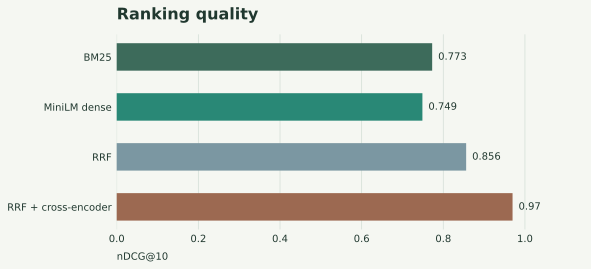

In [9]:
assert len(records) == len(queries) * len(ARMS)
lookup = {(row["case_id"], row["method"]): row for row in records}
assert len(lookup) == len(records)
for case in queries:
    fused = lookup[case["id"], "RRF"]
    rescored = lookup[case["id"], "RRF + cross-encoder"]
    assert set(fused["ranking"]) == set(rescored["ranking"])
    assert fused["recall_at_shortlist"] == rescored["recall_at_shortlist"]
assert quality(["a", "b"], {"a"})["ndcg_at_10"] == 1
assert quality(["a", "b"], {"c"})["zero_hit"]
assert score_answer(anchor, read_top_passages(anchor, anchor["evidence"])) == 1
assert read_top_passages({**anchor, "role": "guest"}, anchor["evidence"])["decision"] == "deny"
assert read_top_passages({**anchor, "tenant": "outside"}, anchor["evidence"])["decision"] == "deny"
for case in queries:
    assert score_answer(case, read_top_passages(case, case["evidence"])) == 1, case["id"]

by_group = defaultdict(list)
for row in records:
    by_group[row["method"], row["slice"]].append(row)
    by_group[row["method"], "all"].append(row)

outcome_labels = ("shortlist_miss", "position_miss", "reader_miss", "strict_pass")
score_fields = ("recall_at_reader_depth", "recall_at_5", "recall_at_shortlist", "ndcg_at_10",
                "all_evidence_in_reader", "all_evidence_in_shortlist", "strict")
scorecard = []
for (method, slice_name), sample in by_group.items():
    wall = [row["online_ms"] for row in sample if row["online_ms"] is not None]
    rank_wall = [row["reranking_ms"] for row in sample if row["reranking_ms"] is not None]
    input_tokens = {
        kind: [row[kind] for row in sample if row[kind] is not None]
        for kind in ("query_embedding_input_tokens", "reranker_input_tokens")
    }
    scorecard.append({
        "method": method, "slice": slice_name, "queries": len(sample),
        "families": len({row["family"] for row in sample}),
        **{field: mean(row[field] for row in sample) for field in score_fields},
        "zero_hits": sum(row["zero_hit"] for row in sample),
        "outcomes": {outcome: sum(row["outcome"] == outcome for row in sample) for outcome in outcome_labels},
        "median_online_ms": median(wall) if wall else None,
        "p95_online_ms": percentile_95(wall) if wall else None,
        "p95_reranking_ms": percentile_95(rank_wall) if rank_wall else None,
        **{f"median_{kind}": median(tokens) if tokens else None for kind, tokens in input_tokens.items()},
    })

comparisons = []
for candidate, incumbent in (("MiniLM dense", "BM25"), ("RRF", "BM25"), (ARMS[-1], "RRF")):
    for metric in ("strict", "all_evidence_in_reader"):
        candidate_scores = [lookup[case["id"], candidate][metric] for case in queries]
        incumbent_scores = [lookup[case["id"], incumbent][metric] for case in queries]
        comparisons.append({
            "candidate": candidate, "incumbent": incumbent, "metric": metric,
            "wins": sum(new > old for new, old in zip(candidate_scores, incumbent_scores, strict=True)),
            "losses": sum(new < old for new, old in zip(candidate_scores, incumbent_scores, strict=True)),
            **paired_interval(queries, candidate_scores, incumbent_scores),
        })

settings = {
    "query_count": len(queries), "family_count": len({case["family"] for case in queries}),
    "variants": sorted(VARIANTS), "release_used": False,
    "development_sha256": SPLIT_MANIFEST["dev"]["sha256"], "document_sha256": digest(documents),
    "documents": len(documents), "documents_by_tenant": {tenant: len(keys) for tenant, keys in ids_by_tenant.items()},
    "shortlist": SHORTLIST, "answer_depth": ANSWER_DEPTH, "ndcg_depth": DISPLAY_CUTOFF,
    "fusion_offset": FUSION_OFFSET, "embed_batch": EMBED_BATCH, "rerank_batch": RERANK_BATCH,
    "max_pair_tokens": MAX_PAIR_TOKENS, "bootstrap_draws": 1500, "bootstrap_seed": 401,
    "embeddings": MODEL_IDS["embedding"], "reranker": MODEL_IDS["reranker"],
}
all_rows = [row for row in scorecard if row["slice"] == "all"]
print("Settings:", settings)
print("Setup and memory:", setup)
print("Overall scorecard:", all_rows)
print("Scorecard by query type:", [row for row in scorecard if row["slice"] != "all"])
print("Paired family intervals:", comparisons)
print("Opening ticket and wording change:", [
    (row["case_id"], row["method"], row["request"], row["relevant_ranks"], row["actual"]) for row in probe
])
for method in ARMS:
    miss = next((row for row in records if row["method"] == method and not row["strict"]), None)
    if miss:
        print("Representative miss:", miss["case_id"], method, miss["outcome"],
              miss["ranking"][:ANSWER_DEPTH], miss["expected"], miss["actual"])

save("summary", {"mode": "fixture" if COURSE_SMOKE else "measured", "settings": settings,
                 "setup": setup, "scorecard": scorecard, "paired": comparisons})
save("records", {"decisions": records, "opening_pair": probe, "documents": documents})
if not COURSE_SMOKE:
    chart("Ranking quality", [row["method"] for row in all_rows],
          [row["ndcg_at_10"] for row in all_rows], "nDCG@10")

## Check the result

Open the records for F250-00 and its wording change. Find the current
manual's place in each ranking before looking at the answer. Check which
misses occur before reranking could help. Then compare the improvement in
strict outcomes with the additional wall time and GPU memory.

[Read the lesson](https://docs.recohut.com/courses/advanced-ai-systems-engineering/2-build-the-evidence-layer/05-build-and-rerank-a-shortlist).

## Read the result

Inspect the per-case records in `evidence/` before drawing a conclusion from an aggregate. Use the printed sample size, split and hardware when comparing it with another run.

- [MTEB: Massive Text Embedding Benchmark](https://arxiv.org/abs/2210.07316)
- [Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks](https://arxiv.org/abs/1908.10084)